
# Lab 03 – Developing a Tiny Transformer Language Model

## Task 1 – Load and Explore the Dataset


In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset 

# Set random seed for reproducibility
torch.manual_seed(42)

# Select CPU or GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


# Stream the first 1000 stories without downloading the full dataset
stream = load_dataset(
    "roneneldan/TinyStories",
    split="train",
    streaming=True
)

stories = list(stream.take(1000))

# Convert the streamed stories into a Hugging Face Dataset
from datasets import Dataset

dataset = Dataset.from_list(stories)


# Display dataset information
print(dataset)
print("Total stories:", len(dataset))

Device: cpu


Dataset({
    features: ['text'],
    num_rows: 1000
})
Total stories: 1000


In [ ]:
# Display the first three stories
for i in range(3):
    print(f"\nStory {i + 1}:")
    print(dataset[i]["text"])
    print("-" * 50)


Story 1:
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.
--------------------------------------------------

Story 2:
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the par

In [ ]:
# Calculate story lengths in characters
story_lengths = [len(story["text"]) for story in dataset]

print("Number of stories:", len(story_lengths))
print("Average story length:", round(sum(story_lengths) / len(story_lengths), 2))
print("Shortest story:", min(story_lengths))
print("Longest story:", max(story_lengths))

Number of stories: 1000
Average story length: 941.64
Shortest story: 274
Longest story: 4123


## Task 2 – Preprocess the Text and Character-Level Tokenisation

In [ ]:
# Split 1000 stories into training and validation sets
dataset_split = dataset.train_test_split(
    test_size=0.1,
    seed=42
)

# Combine stories into text for each set
train_text = "\n".join(dataset_split["train"]["text"])
val_text = "\n".join(dataset_split["test"]["text"])

# Display dataset sizes
print("Training stories:", len(dataset_split["train"]))
print("Validation stories:", len(dataset_split["test"]))


Training stories: 900
Validation stories: 100


In [5]:
# Create character vocabulary
chars = sorted(set(train_text + val_text))
vocab_size = len(chars)

# Map characters to integer IDs and back
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

# Encode text into numerical IDs
def encode(text):
    return [stoi[ch] for ch in text]

# Decode numerical IDs into text
def decode(ids):
    return "".join(itos[int(i)] for i in ids)

# Convert training and validation text into tensors
train_data = torch.tensor(
    encode(train_text), dtype=torch.long
)

val_data = torch.tensor(
    encode(val_text), dtype=torch.long
)

print("Vocabulary size:", vocab_size)
print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))  

Vocabulary size: 75
Training tokens: 844154
Validation tokens: 98484


In [6]:
# Test the tokenizer
sample_text = "Once upon a time"

encoded_sample = encode(sample_text)
decoded_sample = decode(encoded_sample)

print("Original text:", sample_text)
print("Encoded text:", encoded_sample)
print("Decoded text:", decoded_sample)

Original text: Once upon a time
Encoded text: [31, 56, 45, 47, 1, 63, 58, 57, 56, 1, 43, 1, 62, 51, 55, 47]
Decoded text: Once upon a time



## Task 3 – Preparing Training Data


In [7]:
# Set sequence length and batch size
block_size = 64
batch_size = 32

# Function to generate input and target sequences
def get_batch(split_name):
    source = train_data if split_name == "train" else val_data

    # Random starting positions
    starts = torch.randint(
        len(source) - block_size - 1,
        (batch_size,)
    )

    # Input sequences
    x = torch.stack([
        source[i:i + block_size] for i in starts
    ])

    # Target sequences shifted by one character
    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in starts
    ])

    return x.to(device), y.to(device)

# Generate one training batch
x, y = get_batch("train")

# Display sequence shapes
print("Input shape:", x.shape)
print("Target shape:", y.shape)

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])


In [ ]:
# Sample input and target sequence
print("Sample Input:")
print(decode(x[0][:50].tolist()))

print("\nSample Target:")
print(decode(y[0][:50].tolist()))

Sample Input:
little girl thanked him and took the flowers home.

Sample Target:
ittle girl thanked him and took the flowers home. 



## Task 4 – Build the Transformer Architecture

In [ ]:
# Define a tiny character-level Transformer
class TinyTransformer(nn.Module):
    def __init__(self, num_heads=2):
        super().__init__()

        # Token embeddings
        self.token_emb = nn.Embedding(vocab_size, 64)

        # Positional embeddings
        self.pos_emb = nn.Embedding(block_size, 64)

        # Transformer layer with multi-head attention, feed-forward network, residual connections, and layer normalization
        layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            activation="gelu"
        )

        # Stack two Transformer layers
        self.blocks = nn.TransformerEncoder(
            layer,
            num_layers=2
        )

        # Output layer predicts the next character
        self.lm_head = nn.Linear(64, vocab_size)

    def forward(self, idx):
        B, T = idx.shape

        # Position indices
        positions = torch.arange(T, device=idx.device)

        # Combine token and positional embeddings
        x = self.token_emb(idx) + self.pos_emb(positions)

        # Causal mask prevents attention to future tokens
        mask = torch.triu(
            torch.ones(
                T, T,
                device=idx.device,
                dtype=torch.bool
            ),
            diagonal=1
        )

        # Apply masked Transformer layers
        x = self.blocks(x, mask=mask)

        # Predict vocabulary logits at each position
        return self.lm_head(x)
    
print("TinyTransformer architecture defined successfully.")

TinyTransformer architecture defined successfully.


## Task 5 – Initialize the Model

In [11]:
# Initialize the Transformer model
model = TinyTransformer().to(device)

# Display the number of trainable parameters
num_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Number of parameters:", num_parameters)
print("Model device:", device) 

Number of parameters: 80715
Model device: cpu


In [12]:
# Define the loss function
criterion = nn.CrossEntropyLoss()

# Configure the AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: AdamW


## Task 6 – Train the Transformer Model

In [13]:
# Lists to store training and validation losses
train_history = []
val_history = []

# Function to evaluate the model
@torch.no_grad()
def evaluate(split_name, num_batches=10):
    model.eval()
    losses = []

    for _ in range(num_batches):
        x, y = get_batch(split_name)

        logits = model(x)

        loss = criterion(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        losses.append(loss.item())

    model.train()
    return sum(losses) / len(losses)

In [14]:
# Training configuration
num_epochs = 15
steps_per_epoch = 100

# Train the Transformer
for epoch in range(num_epochs):
    model.train()
    total_loss = 0.0

    for step in range(steps_per_epoch):
        # Get a training batch
        x, y = get_batch("train")

        # Forward pass
        logits = model(x)

        # Calculate cross-entropy loss
        loss = criterion(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        # Backpropagation and parameter updates
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Calculate average training and validation loss
    train_loss = total_loss / steps_per_epoch
    val_loss = evaluate("val", num_batches=10)

    # Store losses for Task 7
    train_history.append(train_loss)
    val_history.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f} | "
        f"Validation loss: {val_loss:.3f}",
        flush=True
    )

Epoch 01 | Train loss: 2.893 | Validation loss: 2.526
Epoch 02 | Train loss: 2.411 | Validation loss: 2.337
Epoch 03 | Train loss: 2.288 | Validation loss: 2.227
Epoch 04 | Train loss: 2.172 | Validation loss: 2.124
Epoch 05 | Train loss: 2.058 | Validation loss: 2.027
Epoch 06 | Train loss: 1.969 | Validation loss: 1.918
Epoch 07 | Train loss: 1.894 | Validation loss: 1.850
Epoch 08 | Train loss: 1.831 | Validation loss: 1.804
Epoch 09 | Train loss: 1.771 | Validation loss: 1.738
Epoch 10 | Train loss: 1.727 | Validation loss: 1.694
Epoch 11 | Train loss: 1.687 | Validation loss: 1.673
Epoch 12 | Train loss: 1.647 | Validation loss: 1.654
Epoch 13 | Train loss: 1.619 | Validation loss: 1.610
Epoch 14 | Train loss: 1.592 | Validation loss: 1.605
Epoch 15 | Train loss: 1.567 | Validation loss: 1.546


In [15]:
print("Completed epochs:", len(train_history))
print("Final training loss:", round(train_history[-1], 4))
print("Final validation loss:", round(val_history[-1], 4))

Completed epochs: 15
Final training loss: 1.5671
Final validation loss: 1.5457


## Task 7 – Monitor Training

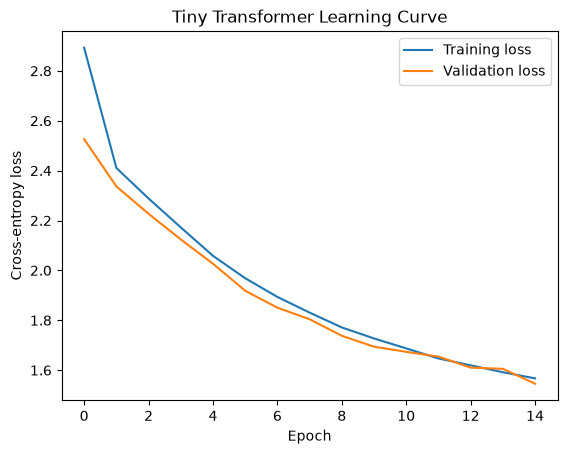

In [17]:
import matplotlib.pyplot as plt

plt.plot(train_history, label="Training loss")
plt.plot(val_history, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer Learning Curve")
plt.legend()

# Save the graph inside Lab03/results
plt.savefig("../results/Training_Loss_Curve.png", dpi=150, bbox_inches="tight")

plt.show() 

## Task 8 – Evaluate the Model

In [18]:
# Calculate validation loss
val_loss = evaluate("val", num_batches=20)

# Calculate perplexity from validation loss
val_perplexity = math.exp(val_loss)

# Display evaluation results
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation perplexity: {val_perplexity:.2f}") 

Validation loss: 1.5776
Validation perplexity: 4.84



## Task 9 – Generate Stories


In [19]:
# Generate text using the trained Transformer
@torch.no_grad()
def generate(prompt, max_new_chars=200):
    model.eval()

    # Convert the starting prompt into character IDs
    ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    # Generate one character at a time
    for _ in range(max_new_chars):

        # Keep the most recent characters within block_size
        x = ids[:, -block_size:]

        # Predict the next character
        logits = model(x)

        # Convert logits to probabilities
        probs = F.softmax(logits[:, -1, :], dim=-1)

        # Sample the next character
        next_id = torch.multinomial(probs, num_samples=1)

        # Append the predicted character
        ids = torch.cat([ids, next_id], dim=1)

    return decode(ids[0].tolist())

print("Story generation function created.") 

Story generation function created.


In [20]:
# Generate a story from a starting prompt
prompt = "Once upon a time"

generated_story = generate(
    prompt,
    max_new_chars=200
)

print("Starting Prompt:", prompt)
print("\nGenerated Story:\n")
print(generated_story) 

Starting Prompt: Once upon a time

Generated Story:

Once upon a time. One little forr. She dina looke aind her. When unded somes ascall Lily palood aved dfante! Salloaroud. Cand theire bugirl be meas mings in into plow on liconrot it. They liked que a be helps and sai


In [21]:
# Generate text with a different starting prompt
second_prompt = "There was a little"

second_story = generate(
    second_prompt,
    max_new_chars=200
)

print("Second Generated Story:\n")
print(second_story) 

Second Generated Story:

There was a little girl not them and truck with the pile.

Soand plaing goods. He she goer. It liked to hunt ig ands ving not ho plappy.

Tim the poa on arouse. His dads wantty gosun.
Onci there there dad. That wantic 


In [22]:
from pathlib import Path

# Save generated stories in Lab03/results
results_dir = Path.cwd().parent / "results"
results_dir.mkdir(parents=True, exist_ok=True)

output_file = results_dir / "Generated_Stories.txt"

with open(output_file, "w", encoding="utf-8") as f:
    f.write("Task 9 – Generated Stories\n\n")
    f.write("Story 1:\n")
    f.write(generated_story)
    f.write("\n\nStory 2:\n")
    f.write(second_story)

print("Stories saved to:", output_file) 

Stories saved to: c:\Users\DELL\OneDrive\Documents\LLM-Practical-Portfolio\Lab03\results\Generated_Stories.txt



## Task 10 – Experiment with Model Settings


In [23]:
# Keep the original trained model for comparison
baseline_model = model

baseline_train_history = train_history.copy()
baseline_val_history = val_history.copy()

print("Original model preserved.")
print("Original attention heads: 2")
print("Completed epochs:", len(baseline_train_history)) 

Original model preserved.
Original attention heads: 2
Completed epochs: 15


In [25]:
# Create a new Transformer with 4 attention heads
torch.manual_seed(42)

comparison_model = TinyTransformer(num_heads=4).to(device)

comparison_optimizer = torch.optim.AdamW(
    comparison_model.parameters(),
    lr=0.001
)

comparison_train_history = []

# Train using the same epoch and step settings
for epoch in range(15):
    comparison_model.train()
    total_loss = 0.0

    for step in range(100):
        x, y = get_batch("train")

        logits = comparison_model(x)

        loss = criterion(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        comparison_optimizer.zero_grad()
        loss.backward()
        comparison_optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / 100
    comparison_train_history.append(train_loss)

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train loss: {train_loss:.3f}",
        flush=True
    )

Epoch 01 | Train loss: 2.884
Epoch 02 | Train loss: 2.418
Epoch 03 | Train loss: 2.308
Epoch 04 | Train loss: 2.225
Epoch 05 | Train loss: 2.132
Epoch 06 | Train loss: 2.064
Epoch 07 | Train loss: 2.000
Epoch 08 | Train loss: 1.931
Epoch 09 | Train loss: 1.876
Epoch 10 | Train loss: 1.818
Epoch 11 | Train loss: 1.768
Epoch 12 | Train loss: 1.728
Epoch 13 | Train loss: 1.689
Epoch 14 | Train loss: 1.661
Epoch 15 | Train loss: 1.640


In [26]:
# Create shared validation batches
torch.manual_seed(123)
validation_batches = [get_batch("val") for _ in range(20)]

@torch.no_grad()
def compare_loss(test_model):
    test_model.eval()
    losses = []

    for x, y in validation_batches:
        logits = test_model(x)

        loss = criterion(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )
        losses.append(loss.item())

    return sum(losses) / len(losses)

baseline_loss = compare_loss(baseline_model)
comparison_loss = compare_loss(comparison_model)

print(f"Original model (2 heads): {baseline_loss:.4f}")
print(f"Comparison model (4 heads): {comparison_loss:.4f}") 

Original model (2 heads): 1.5855
Comparison model (4 heads): 1.6387


In [27]:
# Generate text from the same prompt
prompt = "Once upon a time"

# Save the active model
original_model = model

try:
    torch.manual_seed(42)

    # Generate using original model
    model = baseline_model
    baseline_story = generate(prompt, max_new_chars=200)

    torch.manual_seed(42)

    # Generate using comparison model
    model = comparison_model
    comparison_story = generate(prompt, max_new_chars=200)

finally:
    # Restore the original trained model
    model = original_model

print("ORIGINAL MODEL - 2 ATTENTION HEADS")
print(baseline_story)

print("\nCOMPARISON MODEL - 4 ATTENTION HEADS")
print(comparison_story) 

ORIGINAL MODEL - 2 ATTENTION HEADS
Once upon a time livest hes and leoopp." I's mes up onsiddy. He want it it a da1ntsed them didn't's then and it t'm kee, then for.
Onâ Ben a like. They you we to called something longl. Her broked on.

Ben and and hi

COMPARISON MODEL - 4 ATTENTION HEADS
Once upon a time lived fliends and they ifull mumming selittle on and could and Bat her was mall youn hird have t's feelworre famberf asked a say. They yist.

Suckaaw to play for looold yourn the to name a carefin hi
